<a href="https://colab.research.google.com/github/AnuMaryJohn/Python-Projects/blob/main/Assignment_6_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 6 - Linear Regression

## Loading and Preprocessing

In [1]:
# To import necessary mathematical operation and data visualisation libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
# To fetch data from sklearn datasets
from sklearn.datasets import fetch_california_housing
# To Import preprocessing libraries
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer # not needed as data doesnot have any categorical variable.
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler # not needed
from sklearn.preprocessing import PolynomialFeatures
# To import Regression algorithms
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
# To import evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
cal_housing=fetch_california_housing()
print(cal_housing.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

### Convert the dataset into a pandas DataFrame.

In [3]:
df=pd.DataFrame(data=cal_housing.data,columns=cal_housing.feature_names)
df["MedHouseValue"]=cal_housing.target
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseValue
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
df.shape

(20640, 9)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MedInc         20640 non-null  float64
 1   HouseAge       20640 non-null  float64
 2   AveRooms       20640 non-null  float64
 3   AveBedrms      20640 non-null  float64
 4   Population     20640 non-null  float64
 5   AveOccup       20640 non-null  float64
 6   Latitude       20640 non-null  float64
 7   Longitude      20640 non-null  float64
 8   MedHouseValue  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [6]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseValue
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [7]:
# for i in df.columns:
  # print("\nColumn:",i)
  # print("Unique values:",df[i].unique())
  # print("Number of Unique Values:",df[i].nunique())

### Handle missing values if any.

In [8]:
df.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseValue,0


In [9]:
df.duplicated().sum()

np.int64(0)

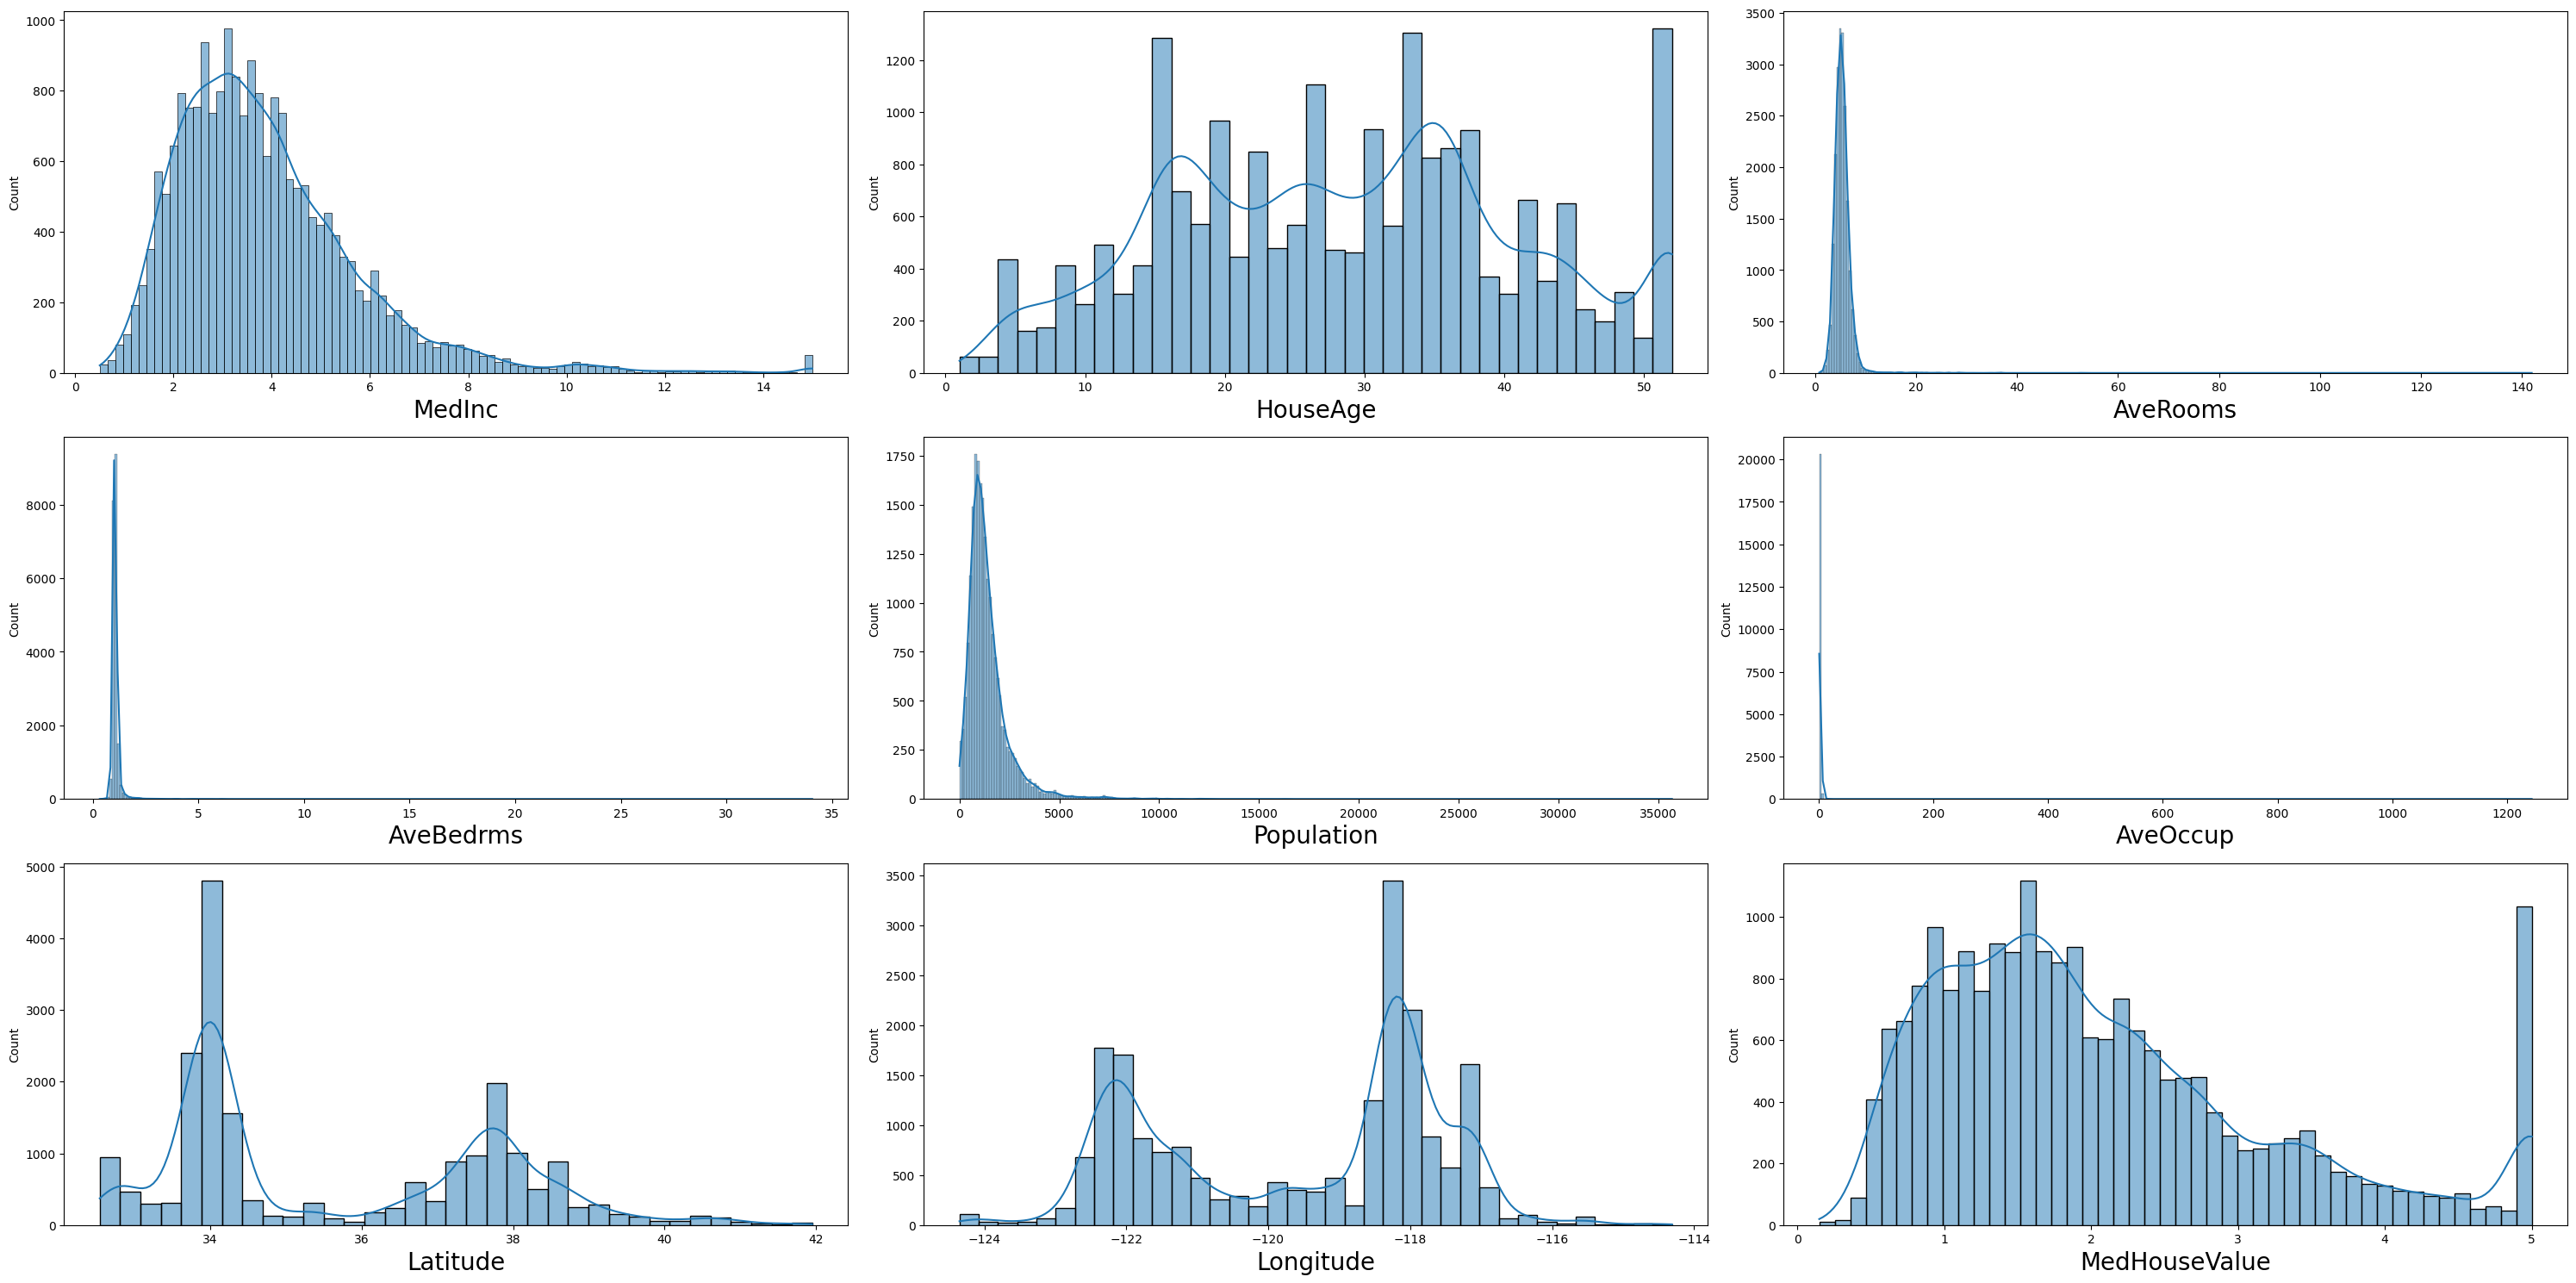

In [10]:
plt.figure(figsize=(30,15))
plotnumber=1
for i in df.columns:
  if plotnumber<=9:
    ax=plt.subplot(3,3,plotnumber)
    sns.histplot(df[i],kde=True)
    plt.xlabel(i,fontsize=20)
  plotnumber+=1
plt.tight_layout()
plt.show()

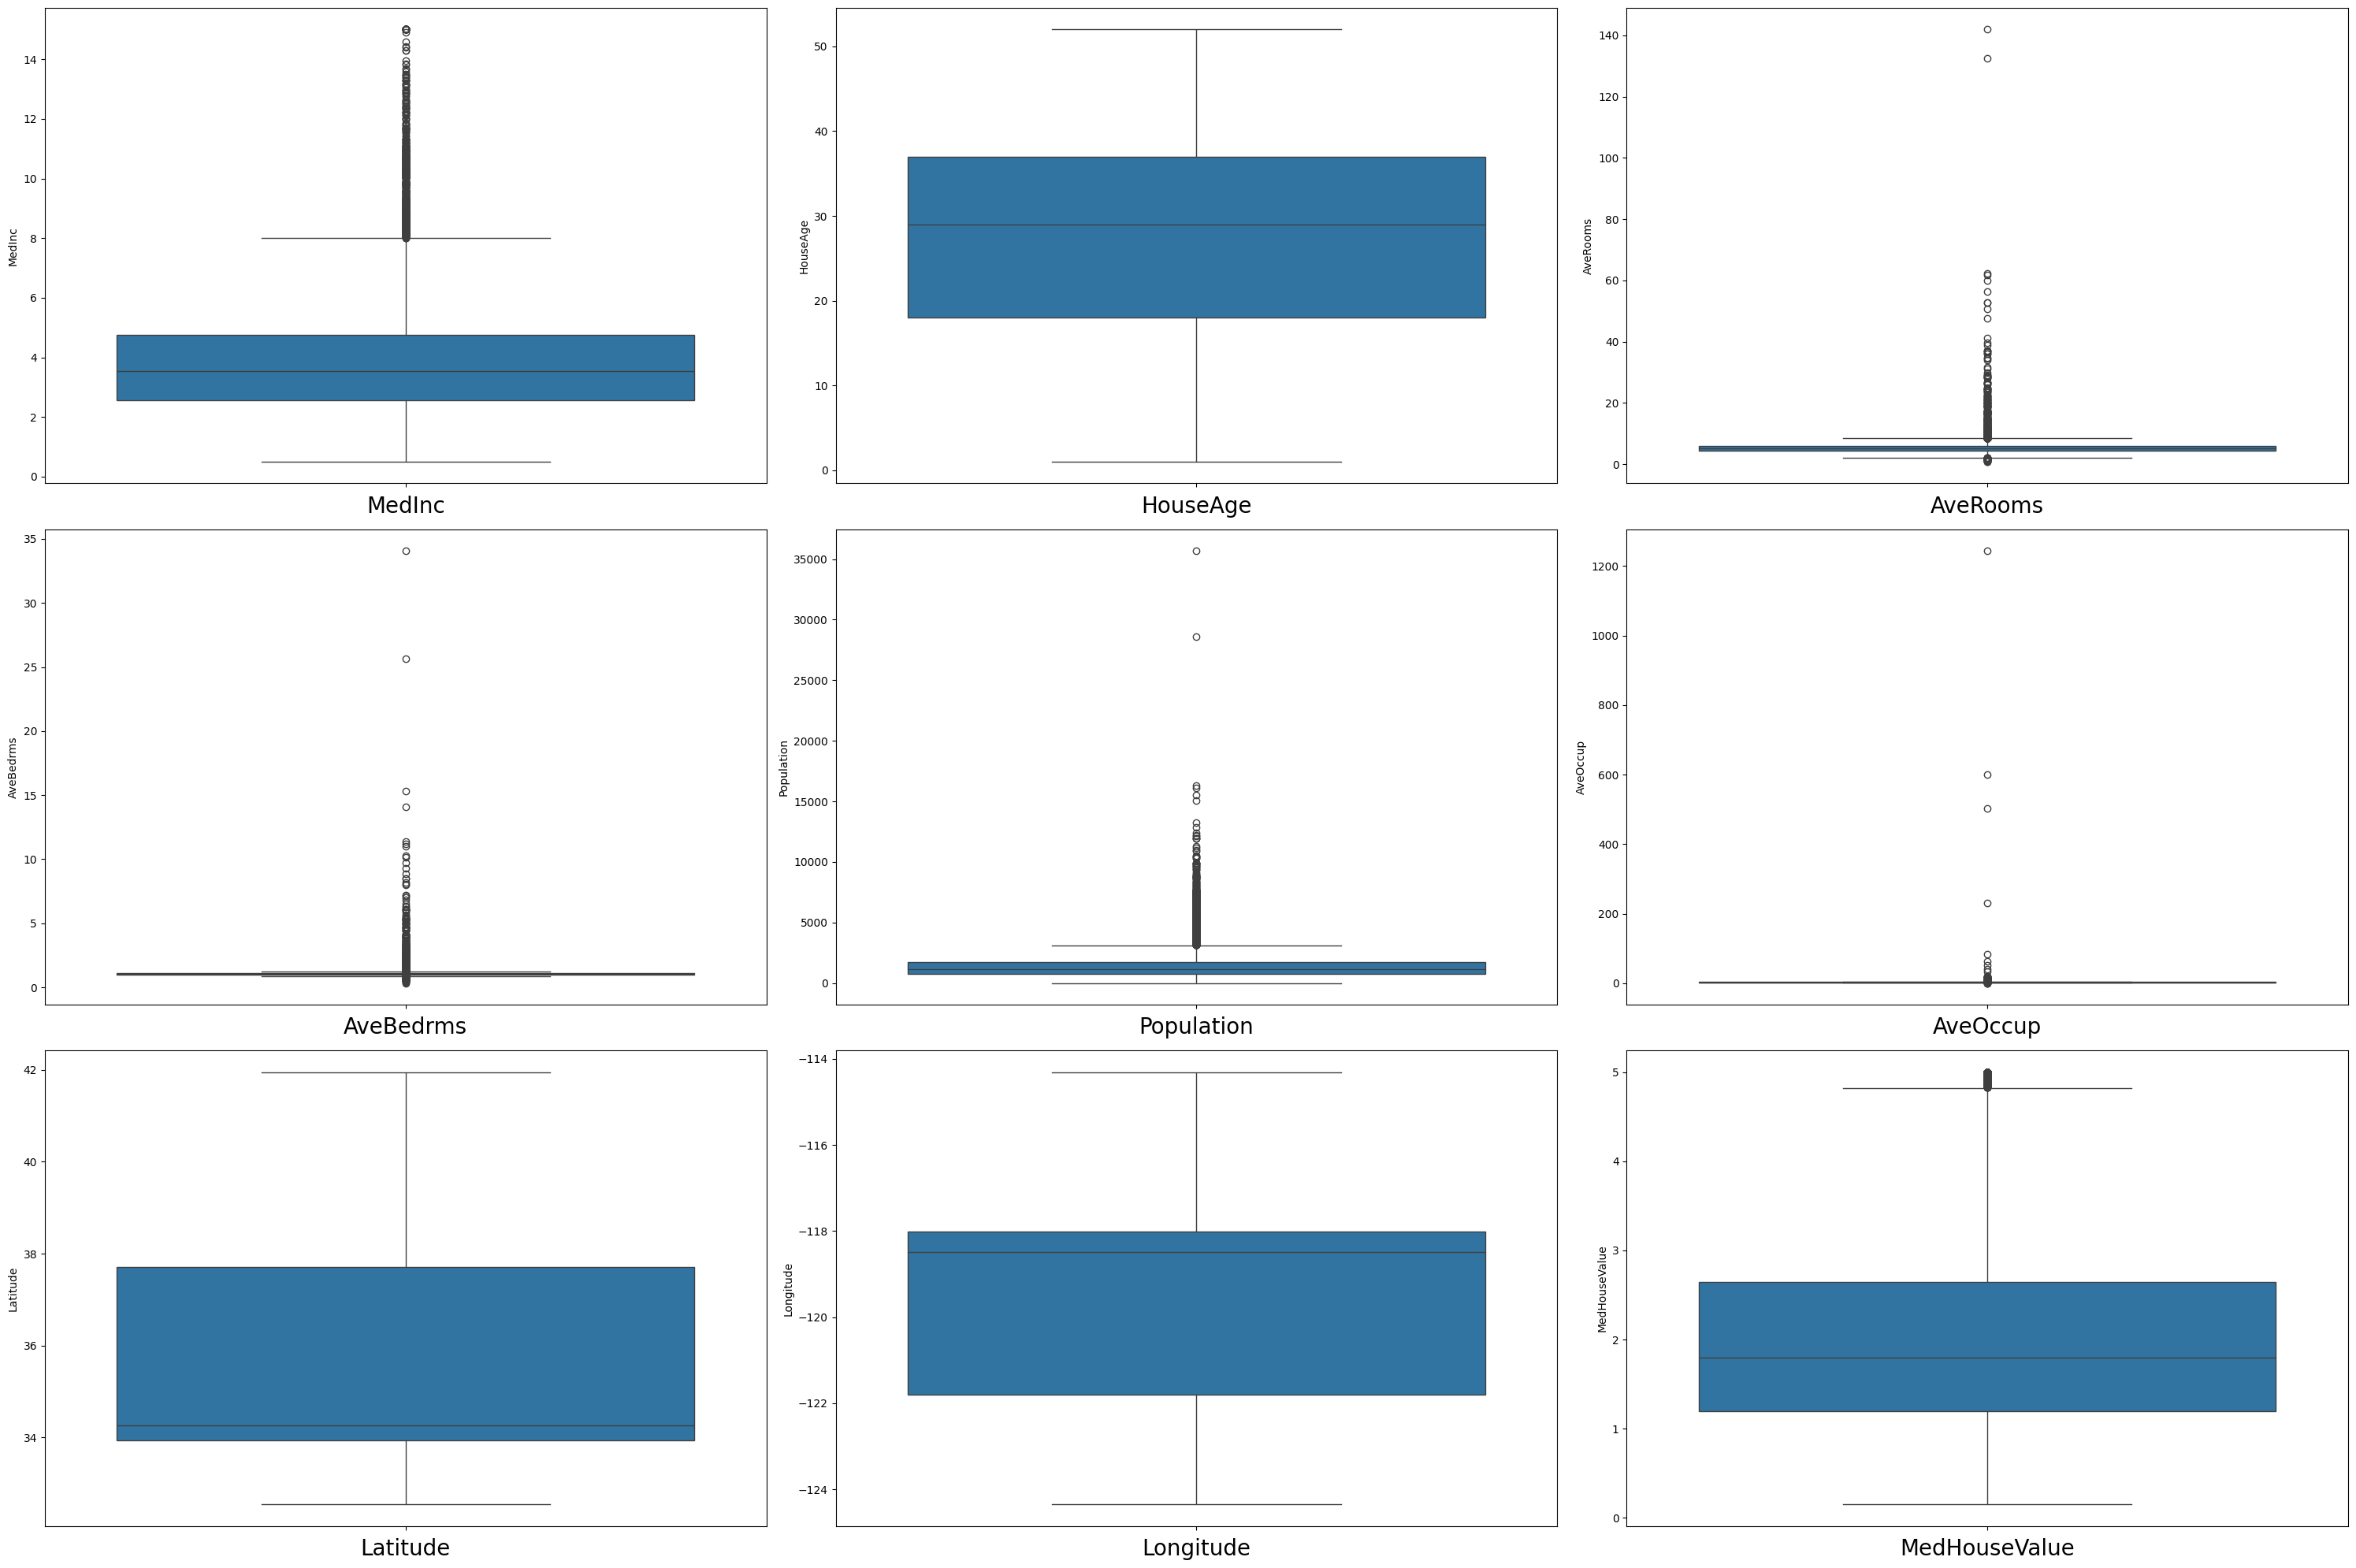

In [11]:
plt.figure(figsize=(30,20))
plotnumber=1
for i in df.columns:
  if plotnumber<=9:
    ax=plt.subplot(3,3,plotnumber)
    sns.boxplot(df[i])
    plt.xlabel(i,fontsize=20)
  plotnumber+=1
plt.tight_layout()
plt.show()

In [12]:
outlier_cols=['MedInc','AveRooms', 'AveBedrms', 'AveOccup']

In [13]:
def remove_outliers_iqr(data, column):
  print("\nColumn:",column)
  q1,q3 = np.percentile(data[column],[25,75])
  print("q1 is :",q1)
  print("q3 is :",q3)

  IQR = q3-q1
  print("IQR is :" ,IQR)

  lower_limit = q1-(1.5*IQR)
  upper_limit = q3+(1.5*IQR)
  outliers=data[column][(data[column]<lower_limit) | (data[column]>upper_limit)]
  print(column, ":", len(outliers))

  data[column]=np.where(data[column]>upper_limit,upper_limit,data[column])
  data[column]=np.where(data[column]<lower_limit,lower_limit,data[column])


In [14]:
for c in outlier_cols:
  remove_outliers_iqr(df,c)


Column: MedInc
q1 is : 2.5633999999999997
q3 is : 4.74325
IQR is : 2.17985
MedInc : 681

Column: AveRooms
q1 is : 4.440716235896959
q3 is : 6.052380952380952
IQR is : 1.6116647164839932
AveRooms : 511

Column: AveBedrms
q1 is : 1.006079046038478
q3 is : 1.099526066350711
IQR is : 0.09344702031223284
AveBedrms : 1424

Column: AveOccup
q1 is : 2.4297411475535755
q3 is : 3.2822609242736216
IQR is : 0.8525197767200461
AveOccup : 711


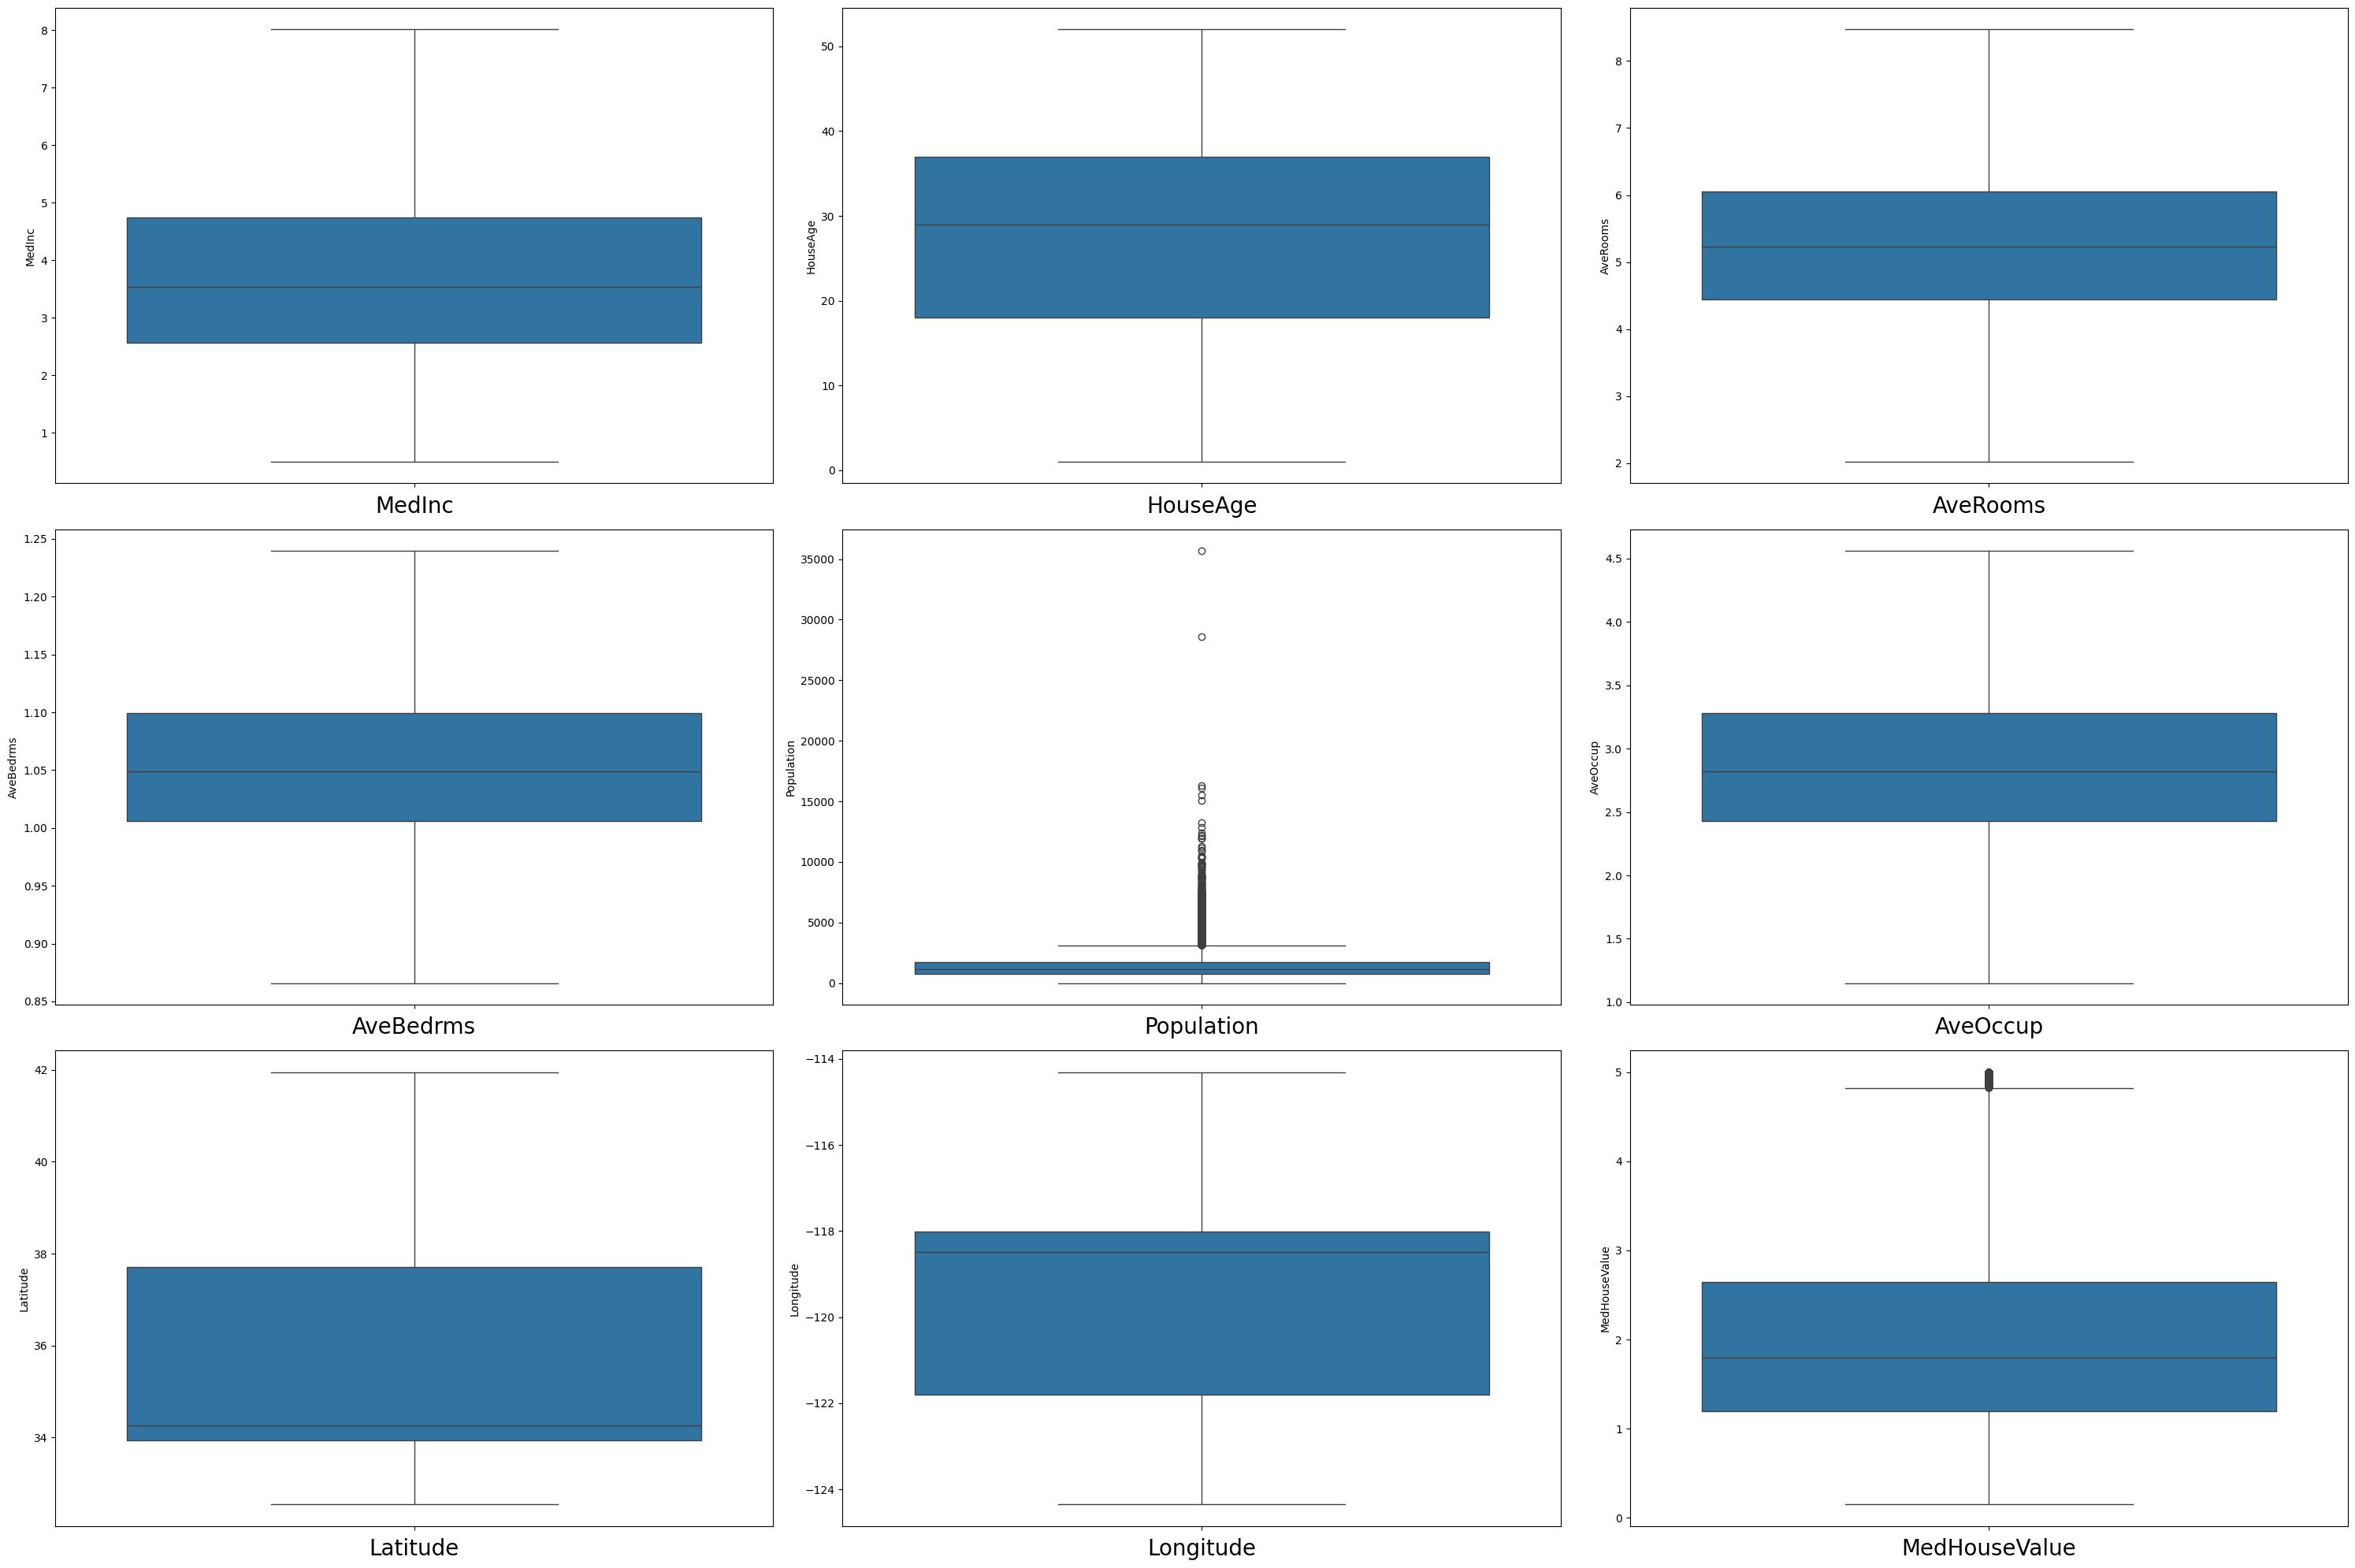

In [15]:
plt.figure(figsize=(30,20))
plotnumber=1
for i in df.columns:
  if plotnumber<=9:
    ax=plt.subplot(3,3,plotnumber)
    sns.boxplot(df[i])
    plt.xlabel(i,fontsize=20)
  plotnumber+=1
plt.tight_layout()
plt.show()

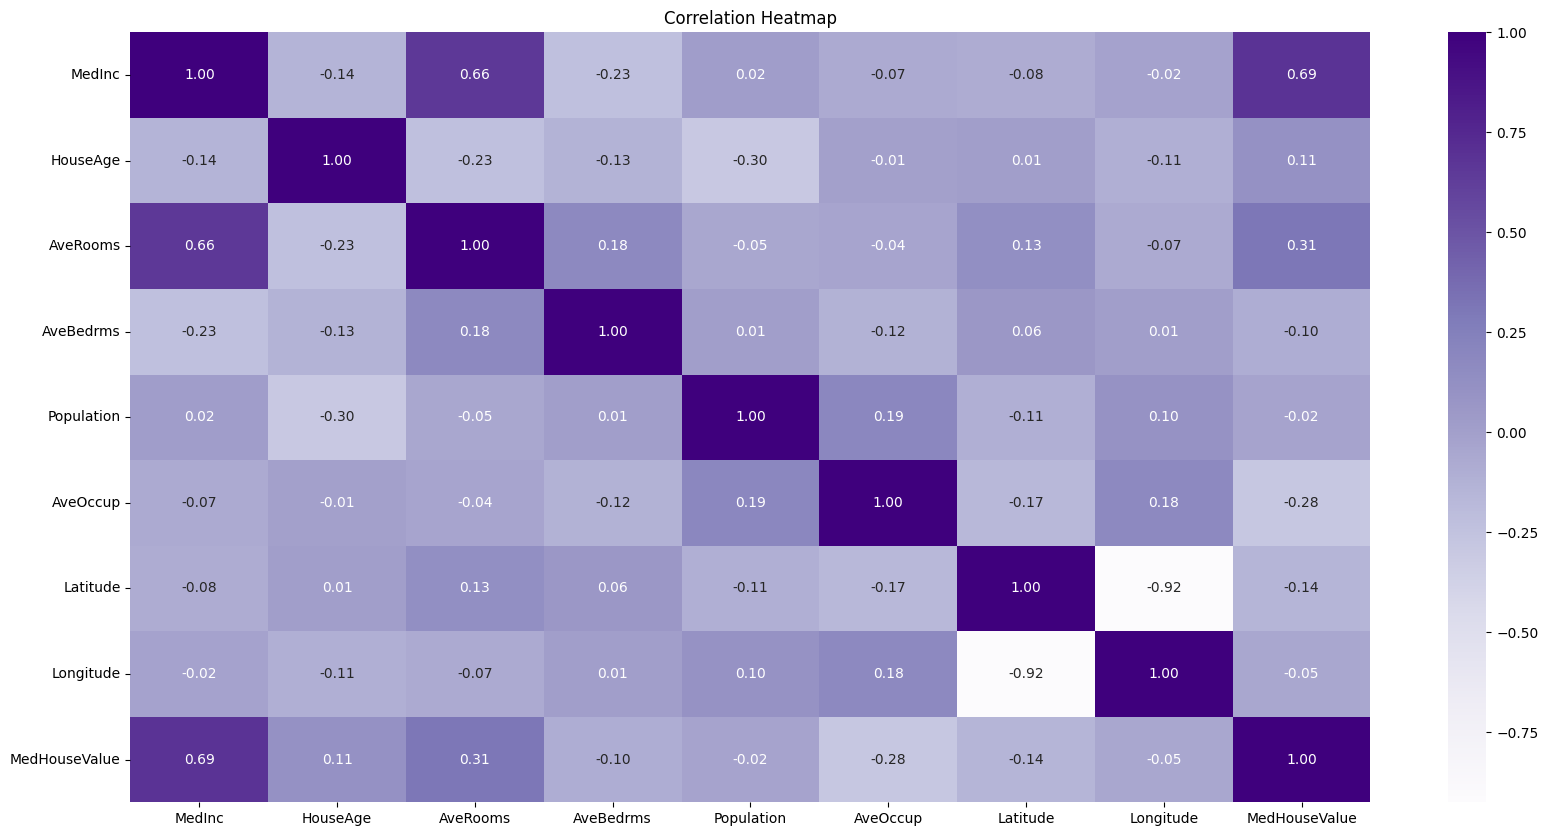

In [16]:
plt.figure(figsize=(20,10))
sns.heatmap(df.corr(),annot=True,fmt=".2f",cmap="Purples")
plt.title("Correlation Heatmap")
plt.show()

In [17]:
x=df.drop("MedHouseValue",axis=1) # features
y=df["MedHouseValue"] # Target

In [18]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

### Perform feature scaling.

In [19]:
std=StandardScaler()
x_train=std.fit_transform(x_train)
x_test=std.transform(x_test)

Data set was fetched from sklearn datasets using fetch command. The dataset has 9 variables with numerical data with 20640 rows. the statistical analysis shows that every variable except house age, latitude and longitude has outliers. None of the variables consist of null values and there is no duplicate data in the data set. Then we plotted the histograms and boxplots to visualise the outlier variables. After plotting Boxplot, it is seen all the variables except house age, latitude and longitude has outliers. Now to handle outliers, we use the IQR method. Also, we do not change the target variable as we are aiming to predict its values. now the variables population also kept as the original but the other variables with outliers were handled using the IQR method. After this, we use the correlation heatmap to visualise the correlation between the different variables and found that there are no significant highly correlated variables in the data. After this we split the data in to test and train sets and feature scaling was done on the data set as the variables are of very different ranges. Now the data set is ready for different algorithm implementation.

## 2. Regression Algorithm Implementation.

### Linear Regression

In [20]:
lr_model=LinearRegression()
lr_model.fit(x_train,y_train)

LinearRegression()

In [21]:
y_pred_train=lr_model.predict(x_train)
y_pred_test=lr_model.predict(x_test)

In [22]:
r2_train=r2_score(y_train,y_pred_train)
r2_test=r2_score(y_test,y_pred_test)
print("R2 Train:",r2_train)
print("R2 Test:",r2_test)

R2 Train: 0.6711239702382121
R2 Test: 0.6459724876965682


Here the R2 Score of both train data and test data are less than 70% but they are both almost same which means that there is underfitting in the data. Which may be because the relationship between the features and the hpuse price is non linear. To deal with the underfitting of the model we use polynomial regression model. Here we use quadratic polynomial regression.

In [23]:
poly=PolynomialFeatures(degree=2,include_bias=False)
x_train_poly=poly.fit_transform(x_train)
x_test_poly=poly.transform(x_test)

In [24]:
poly_model=LinearRegression()
poly_model.fit(x_train_poly,y_train)
y_pred_train_poly=poly_model.predict(x_train_poly)
y_pred_test_poly=poly_model.predict(x_test_poly)

In [25]:
r2_train=r2_score(y_train,y_pred_train_poly)
r2_test=r2_score(y_test,y_pred_test_poly)
print("R2 Train:",r2_train)
print("R2 Test:",r2_test)

R2 Train: 0.7372894168466795
R2 Test: 0.7228206921042994


After the implementation of polynomial regression, we can see that there is an improvement in the score of the two data sets Which indicates a good performance on both datasets.

### Decision Tree Regressor

In [26]:
dtr=DecisionTreeRegressor(random_state=42)
dtr.fit(x_train,y_train)

DecisionTreeRegressor(random_state=42)

In [27]:
y_pred_train_dtr=dtr.predict(x_train)
y_pred_dtr=dtr.predict(x_test)

In [28]:
r2_train=r2_score(y_train,y_pred_train_dtr)
r2_test=r2_score(y_test,y_pred_dtr)
print("R2 Train:",r2_train)
print("R2 Test:",r2_test)

R2 Train: 1.0
R2 Test: 0.6236733301610904


Here the train data score is perfect and the test data score is very low which indiates there is a possible overfitting. To deal with this we can adjust the depth of the model.

In [29]:
dtr=DecisionTreeRegressor(max_depth=8,random_state=42)
dtr.fit(x_train,y_train)

DecisionTreeRegressor(max_depth=8, random_state=42)

In [30]:
y_pred_train_dtr=dtr.predict(x_train)
y_pred_dtr=dtr.predict(x_test)

In [31]:
r2_train=r2_score(y_train,y_pred_train_dtr)
r2_test=r2_score(y_test,y_pred_dtr)
print("R2 Train:",r2_train)
print("R2 Test:",r2_test)

R2 Train: 0.7591658276830059
R2 Test: 0.6773799637160662


After the adjustment of the depth of the model we can see there is an improvement in the performance of the data. Although the performance of the test data is inferior to the train data.

### Random Forest Regressor

In [32]:
rfr=RandomForestRegressor(random_state=42)
rfr.fit(x_train,y_train)

RandomForestRegressor(random_state=42)

In [33]:
y_pred_train_rfr=rfr.predict(x_train)
y_pred_rfr=rfr.predict(x_test)

In [34]:
r2_train=r2_score(y_train,y_pred_train_rfr)
r2_test=r2_score(y_test,y_pred_rfr)
print("R2 Train:",r2_train)
print("R2 Test:",r2_test)

R2 Train: 0.9733485501873574
R2 Test: 0.8053572759097243


Here the test and train score is high, we can conclude that the model performance is good. But the test score is much less than the train score,  which is a difference of 17%.

### Gradient Boosting Regressor

In [35]:
gbr=GradientBoostingRegressor(n_estimators=50,learning_rate=0.1,max_depth=1,random_state=42)
gbr.fit(x_train,y_train)

GradientBoostingRegressor(max_depth=1, n_estimators=50, random_state=42)

In [36]:
y_pred_train_gbr=gbr.predict(x_train)
y_pred_gbr=gbr.predict(x_test)

In [37]:
r2_train=r2_score(y_train,y_pred_train_gbr)
r2_test=r2_score(y_test,y_pred_gbr)
print("R2 Train:",r2_train)
print("R2 Test:",r2_test)

R2 Train: 0.5740584886395186
R2 Test: 0.5499716719486785


Here the model score shows a possible underfitting. This can be reduced by increasing the number of estimator and the depth.

In [38]:
gbr=GradientBoostingRegressor(n_estimators=100,learning_rate=0.1,max_depth=3,random_state=42)
gbr.fit(x_train,y_train)

GradientBoostingRegressor(random_state=42)

In [39]:
y_pred_train_gbr=gbr.predict(x_train)
y_pred_gbr=gbr.predict(x_test)

In [40]:
r2_train=r2_score(y_train,y_pred_train_gbr)
r2_test=r2_score(y_test,y_pred_gbr)
print("R2 Train:",r2_train)
print("R2 Test:",r2_test)

R2 Train: 0.8046820168526032
R2 Test: 0.7776632910663117


After the adjustment of estimators and depth, we can see that the performance of the model was improved treamendously and we can conclude that the performance of the data is good.

### Support Vector Regressor

In [41]:
svr=SVR(kernel="rbf")
svr.fit(x_train,y_train)

SVR()

In [42]:
y_pred_train_svr=svr.predict(x_train)
y_pred_svr=svr.predict(x_test)

In [43]:
r2_train=r2_score(y_train,y_pred_train_svr)
r2_test=r2_score(y_test,y_pred_svr)
print("R2 Train:",r2_train)
print("R2 Test:",r2_test)

R2 Train: 0.7874212910931057
R2 Test: 0.759706845479895


Here the model scores show that the model perfoms fairly good. There is no particular signs of underfitting or overfitting.

If we are looking for a model which best performs for this data set, looking at the r2 score of the test data, it will be random forest regressor method with 80% score.

Also, eventhough the Gradient Boosting regressor method initially shows a possible undefitting, after adjusting the number of estimator, the model performance is increased significantly and if the number of estimator is increased furthur, the model performance can be improved again.

The third best model for this data set is Support Vector Regressor model since the model performance of both the test and train data is fairly good with good r2 score of 75% with out showing any signs of overfitting or underfitting.

## 3. Model Evaluation and Comparison

In [44]:
mae=mean_absolute_error(y_test,y_pred_test)
mse=mean_squared_error(y_test,y_pred_test)
r2=r2_score(y_test,y_pred_test)
print("MAE-LR:",mae)
print("MSE-LR:",mse)
print("R2-LR:",r2)

MAE-LR: 0.5040956621923439
MSE-LR: 0.46392083066670753
R2-LR: 0.6459724876965682


In [45]:
mae=mean_absolute_error(y_test,y_pred_test_poly)
mse=mean_squared_error(y_test,y_pred_test_poly)
r2=r2_score(y_test,y_pred_test_poly)
print("MAE-PR:",mae)
print("MSE-PR:",mse)
print("R2-PR:",r2)

MAE-PR: 0.42332997497188346
MSE-PR: 0.36321825364912474
R2-PR: 0.7228206921042994


In [46]:
mae=mean_absolute_error(y_test,y_pred_dtr)
mse=mean_squared_error(y_test,y_pred_dtr)
r2=r2_score(y_test,y_pred_dtr)
print("MAE-DTr:",mae)
print("MSE-DTr:",mse)
print("R2-DTr:",r2)

MAE-DTr: 0.4510046994989212
MSE-DTr: 0.42276419210687155
R2-DTr: 0.6773799637160662


In [47]:
mae=mean_absolute_error(y_test,y_pred_rfr)
mse=mean_squared_error(y_test,y_pred_rfr)
r2=r2_score(y_test,y_pred_rfr)
print("MAE-RFR:",mae)
print("MSE-RFR:",mse)
print("R2-RFR:",r2)

MAE-RFR: 0.3293980062500001
MSE-RFR: 0.25506157319716366
R2-RFR: 0.8053572759097243


In [48]:
mae=mean_absolute_error(y_test,y_pred_gbr)
mse=mean_squared_error(y_test,y_pred_gbr)
r2=r2_score(y_test,y_pred_gbr)
print("MAE-GBR:",mae)
print("MSE-GBR:",mse)
print("R2-GBR:",r2)

MAE-GBR: 0.3694703013087303
MSE-GBR: 0.2913520195792388
R2-GBR: 0.7776632910663117


In [49]:
mae=mean_absolute_error(y_test,y_pred_svr)
mse=mean_squared_error(y_test,y_pred_svr)
r2=r2_score(y_test,y_pred_svr)
print("MAE-SVR:",mae)
print("MSE-SVR:",mse)
print("R2-SVR:",r2)

MAE-SVR: 0.37477795925481244
MSE-SVR: 0.3148823070929735
R2-SVR: 0.759706845479895


## The best-performing algorithm

The best performing algorithm is the one with low MAE and MSE score and high r2 score:

The Random forest regressor is the Best performing algorithmn with an r2 score of 80% and MAE and MSE values .329 and .255 respectively.

## The worst-performing algorithm

The worst performing algorithm is the one with high MAE and MSE score and low r2 score:

If we do not consider overfitting or underfitting of the model, Gradient boosting regressor with a r2 score of 54% and Decision tree regressor with a r2 score of 62%.

But the under fitting of Gradient boosting regressor can be easily handled. Hence, the worst performing model is Decision tree regressor.

Also even after we adjust the underfitting and overfitting properties of the model, the worst performing algorithmn is Decision tree regressor with an r2 score of 67%.